In [1]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist,squareform
import os
from nltools.mask import expand_mask, roi_to_brain
from nltools.data import Brain_Data, Adjacency

import glob
from tqdm.notebook import tqdm

from nltools.stats import (threshold, 
                           align,
                           fdr, 
                           isc,
                           _calc_pvalue)
from scipy import stats


base_dir = '/Storage/Data/nes_menghan/liquidsword2_materials/behavioral_stability'
current_directory = '/Storage/Data/nes_menghan/code_menghan/NeuroExperience/'
svg_file = 'svg_files' ## svg plots

In [2]:
base_dir = '/Storage/Data/nes_menghan/liquidsword2_materials/behavioral_stability'
time_all = os.path.join(base_dir,'NES_subject_log.xlsx')
time_all = pd.read_excel(time_all,sheet_name='Spring_2019')

In [5]:
time_all_select = time_all.loc[:,['subNum','sessionNum','Date','Time','Accession Num','Scan SID']]

sub_time_gap_all = pd.DataFrame()

for sub_num in range(20):
    sub_name = subj_sids_iteration[sub_num].split('sid')[1]
    sub_name = 'SID'+sub_name
    sub_time = time_all_select[time_all_select['Scan SID'] == sub_name]
    sub_time = sub_time.dropna(axis=0,how='any')  
    sub_time.sort_values("sessionNum",inplace=True)
    
    a = 0
    
    sub_time_gap_time0 = pd.DataFrame(np.array([a,1,subj_sids_iteration[sub_num],sub_time.iloc[0,0]]).reshape(-1,1).T,columns = ['scan time','session','participants','subNum'])
    sub_time_gap_all = pd.concat([sub_time_gap_all,sub_time_gap_time0])
                                 
    for time_gap_time in range(4):
        b = (sub_time.iloc[time_gap_time+1,2]-sub_time.iloc[time_gap_time,2]).days
        a = a+b
        sub_time_gap = pd.DataFrame(np.array([a,time_gap_time+2,subj_sids_iteration[sub_num],sub_time.iloc[0,0]]).reshape(-1,1).T,columns = ['scan time','session','participants','subNum'])


        sub_time_gap_all = pd.concat([sub_time_gap_all,sub_time_gap])



In [6]:
sub_time_gap_all['subNum']=sub_time_gap_all['subNum'].astype(float)
unique_subject = sub_time_gap_all['subNum'].unique().tolist()
unique_subject_int = [int(float(x)) for x in unique_subject]
unique_subject_int

[25, 4, 9, 36, 23, 1, 35, 24, 3, 40, 12, 11, 32, 41, 16, 6, 21, 18, 8, 7]

In [4]:
data_dir = '/Storage/Data/nes_menghan/preprocessed/final/'
subj_sids_list = os.listdir(data_dir)
subj_sids_iteration = []
for subj in subj_sids_list:
    subj_path = os.path.join(data_dir, subj)
    subj_path_sess = os.listdir(subj_path)
    if len(subj_path_sess) == 5:
        subj_sids_iteration.append(subj)
    
    
subj_sids_iteration.remove('sub-sid001215') ###the Timepoints of this subject's third session were fewer than others
subj_sids_iteration.remove('sub-sid001473') ### the fifth

subj_sids_iteration.remove('sub-sid000860') 
subj_sids_iteration.remove('sub-sid001201')  ### head coil issue: HEP
print(len(subj_sids_iteration))
subj_sids_iteration

20


['sub-sid001377',
 'sub-sid001277',
 'sub-sid001280',
 'sub-sid001367',
 'sub-sid000846',
 'sub-sid001274',
 'sub-sid001397',
 'sub-sid001358',
 'sub-sid001276',
 'sub-sid000381',
 'sub-sid001286',
 'sub-sid001282',
 'sub-sid000854',
 'sub-sid001555',
 'sub-sid001291',
 'sub-sid000780',
 'sub-sid001302',
 'sub-sid001296',
 'sub-sid001278',
 'sub-sid000861']

In [7]:
import pandas as pd

onset_movie = os.path.join('/Storage/Data/nes_menghan/', 'code_menghan', 'NeuroExperience','onset_movie.txt')

onset_movie = pd.read_csv(onset_movie,sep='\t').set_index('Movie name')
onset_movie

,Scanning run,Starting TR,Ending TR,Trim_Starting TR,Trim_Ending TR,Entire Onset,Entire Ending
Movie name,,,,,,,
Nature,run1,8,52,3,47,3,47
Asian cake,run1,62,185,57,180,57,180
Ribbon climbing,run1,194,335,189,330,189,330
Kiss me,run1,344,485,339,480,339,480
Syrian,run1,495,584,490,579,490,579
Salad,run2,8,138,3,133,591,721
Angelina Hale,run2,147,277,142,272,730,860
Soccer,run2,285,410,280,405,868,993
Dancing lady,run2,419,529,414,524,1002,1112


In [9]:
big5 = os.path.join(base_dir,'questionnaire_results','big5.csv')
big5 = pd.read_csv(big5)
big5_stability = big5[big5['Subject_ID'].isin(unique_subject_int)]
big5_stability.sort_values("Subject_ID",inplace=True)

/tmp/ipykernel_1022802/2703478598.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  big5_stability.sort_values("Subject_ID",inplace=True)


/tmp/ipykernel_1022802/3799913324.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub_big5_stability.sort_values("Session_Number",inplace=True)
/tmp/ipykernel_1022802/3799913324.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub_big5_stability.sort_values("Session_Number",inplace=True)


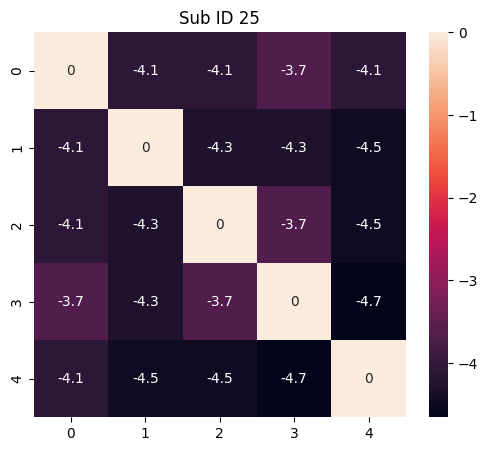

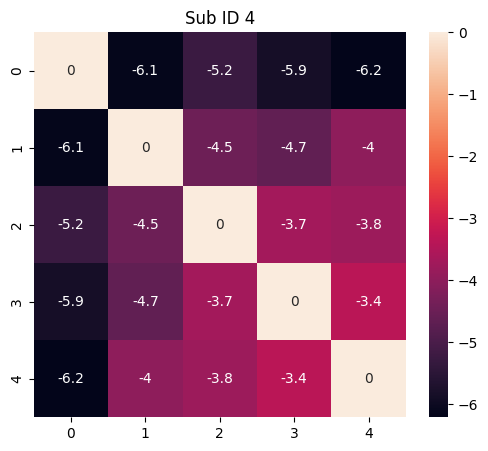

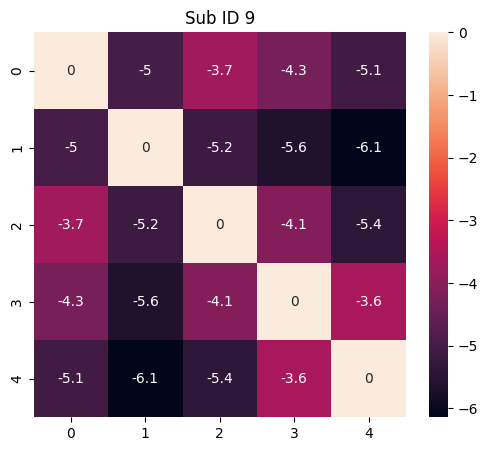

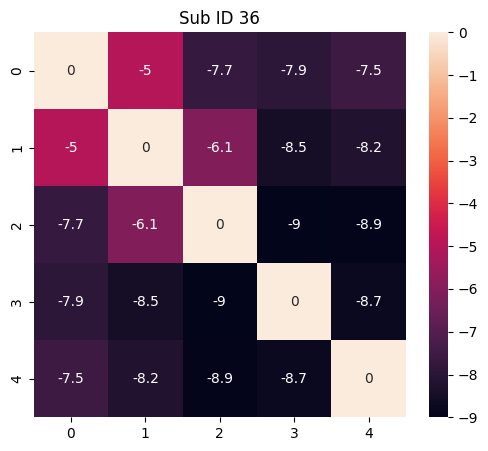

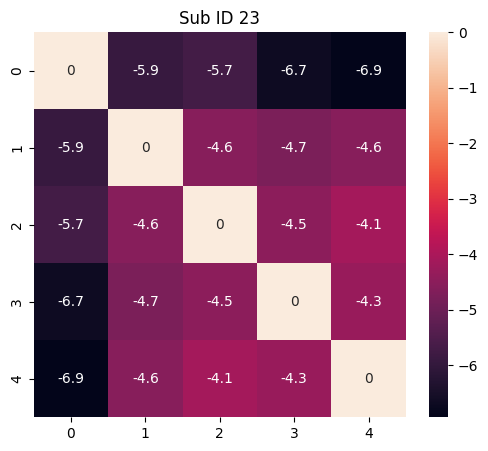

...

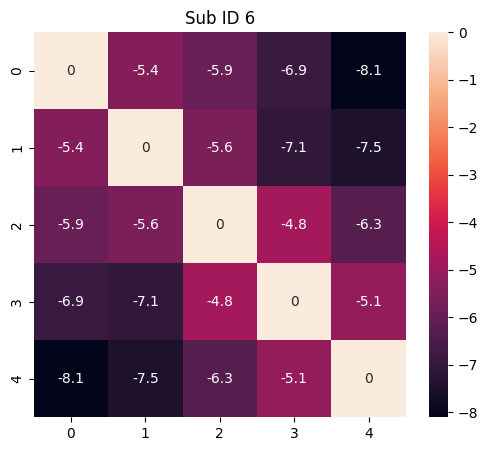

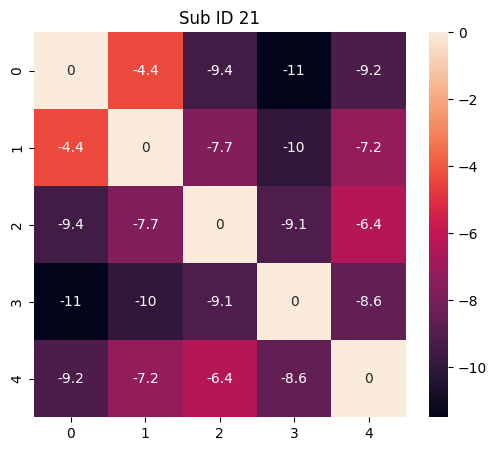

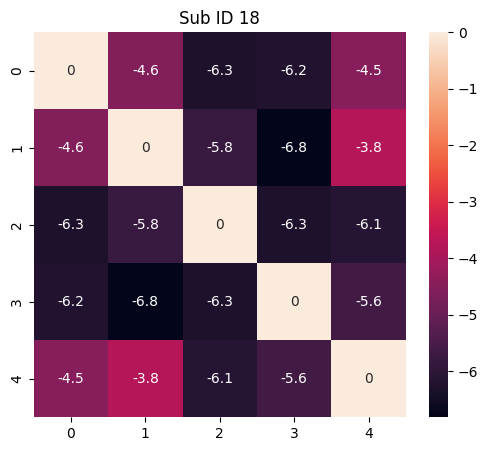

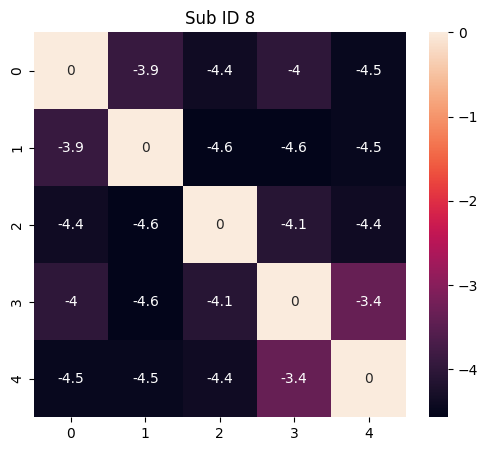

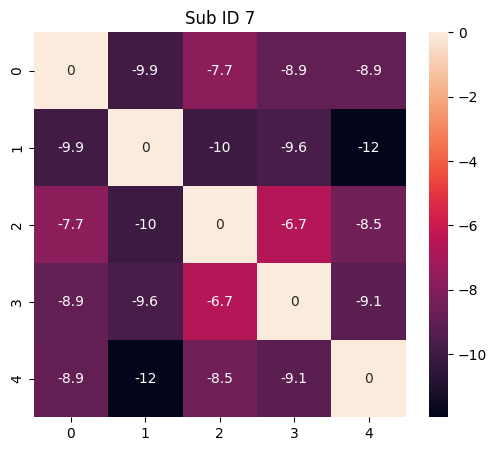

In [10]:
from nltools.data import Brain_Data, Adjacency
from scipy.spatial.distance import pdist,squareform

sub_big5_session_similarity = np.zeros((20,5,5))

for x,sub_ID in enumerate(unique_subject_int):
    sub_big5_stability = big5_stability[big5_stability['Subject_ID'] == sub_ID]
    sub_big5_stability.sort_values("Session_Number",inplace=True)
#     print(sub_big5_stability.iloc[:,:5])
    if sub_ID == 36:
        sub_big5_stability = sub_big5_stability.drop([154])
    
    sub_big5_stability_items = sub_big5_stability.iloc[:,8:68]
    sub_big5_stability_items = sub_big5_stability_items.dropna(axis=1,how='any') 
    
    sub_big5_stability_items_distance = Adjacency(squareform(pdist(sub_big5_stability_items, metric = 'euclidean')), matrix_type="distance")
    sub_big5_stability_items_similarity = Adjacency.distance_to_similarity(sub_big5_stability_items_distance)
    sub_big5_stability_items_similarity = sub_big5_stability_items_similarity.squareform()
    
    sub_big5_session_similarity[x,:,:] = sub_big5_stability_items_similarity
    
    sub_fig, _ = plt.subplots(figsize=(6,5))
    sns.heatmap(sub_big5_stability_items_similarity,annot=True).set(title = 'Sub ID ' + str(sub_ID) )

# for subNum 36, save the measurement date 11/16/2019 for session 4 as it is the true scanning date!

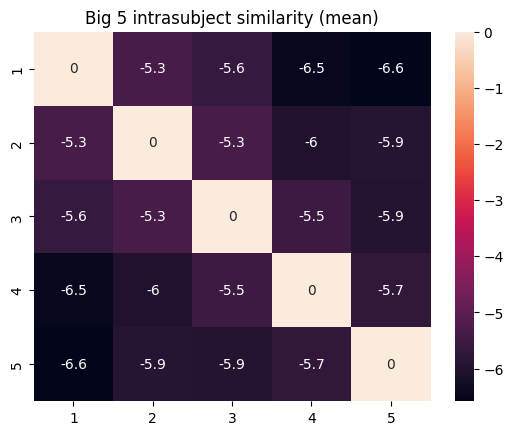

In [83]:
sns.heatmap(sub_big5_session_similarity.mean(axis = 0),annot=True,yticklabels=yticks,xticklabels=yticks).set(title = 'Big 5 intrasubject similarity (mean)')


plt.savefig(os.path.join(current_directory,svg_file,"big_five.svg"), format="svg")


## whole-brain temporal session-by-session similarity and real temporal distance

In [12]:

def temporal_ISC(roi_num):
    session_num = 5


    suball_movie_corr = pd.DataFrame()
    ISC_within_corr_all = []


    for sub_name in tqdm(subj_sids_iteration):
        data_subj_session = pd.DataFrame([])
        isc_data = glob.glob(os.path.join('/Storage/Data/nes_menghan/denoised/Denoised_ROI',f"{sub_name}_ses*_Denoised_ROI_{roi_num}.csv"))
        isc_data.sort()
        for i in range(session_num):
            isc_data_session = pd.read_csv(isc_data[i])
            if len(data_subj_session) == 0:
                data_subj_session = isc_data_session
            else:
                data_subj_session = np.concatenate((data_subj_session,isc_data_session),axis = 1)

        video_corr = []
    #         video_corr_data = []
        for video_label in range(24):
            video_sess = []
            video_onset = onset_movie['Entire Onset'][video_label]-1
            video_end = onset_movie['Entire Ending'][video_label]-1
            video_sess = data_subj_session[video_onset:video_end+1,:] 

            video_data = pd.DataFrame(video_sess)
    #             video_data = video_data.T
            video_data_corr = video_data.corr()
            ISC_within_corr_all.append(video_data_corr.values.tolist())

    ISC_within_corr_all_np = np.array(ISC_within_corr_all)
    ISC_within_corr_all_np_reshape = ISC_within_corr_all_np.reshape(20,24,5,5)
    return ISC_within_corr_all_np_reshape

In [17]:
ROI_corr_big5 = []


for roi_num in range(50):
    ISC_within_corr_all_np_reshape = temporal_ISC(roi_num)
    corr_temporal = pd.DataFrame()
    
    for sub_id,sub_name in enumerate(subj_sids_iteration):
        for video_id in range(24):
            individual_pd_corr = pd.DataFrame()
            session_matrix = ISC_within_corr_all_np_reshape[sub_id,video_id,:,:]
            y_array_trail = session_matrix[np.triu_indices(5, 1)]


            sub_big5_session_similarity_x = sub_big5_session_similarity[sub_id,:,:]
            big5_trail = sub_big5_session_similarity_x[np.triu_indices(5, 1)]
            data = pd.DataFrame(np.array([big5_trail,y_array_trail]).T,columns = ['big5','temporal corr'])
            
            results_corr = data.corr().iloc[0,1]
            individual_pd_corr = pd.DataFrame(np.array([results_corr,sub_name,onset_movie.index[video_id]]).reshape((-1, 3)),columns = ['corr','participants','video'])

            corr_temporal = pd.concat([corr_temporal,individual_pd_corr])


        corr_temporal['corr']=corr_temporal['corr'].astype(float)
        
    ROI_corr_big5.append(corr_temporal['corr'].mean())

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

nltools.data.brain_data.Brain_Data(data=(50, 238955), Y=0, X=(0, 0), mask=MNI152_T1_2mm_brain_mask.nii.gz)

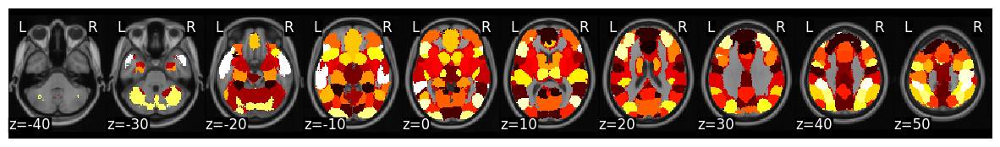

In [19]:
import os
from nltools.mask import expand_mask, roi_to_brain
from nltools.data import Brain_Data, Adjacency

from fnl_tools.stats import (compute_ISC_all_roi,
                             create_average_concordance)
from nltools.prefs import MNI_Template
import warnings
warnings.filterwarnings('ignore')

MNI_Template['resolution'] = '2mm' ## mask specify

base_dir = '/Storage/Data/nes/'

mask = Brain_Data(os.path.join(base_dir, 'code_menghan', 'Mask', 'k50_2mm.nii.gz'))
mask.plot()
#expand this mask into 50 separate regions
mask_x = expand_mask(mask) 
mask_x

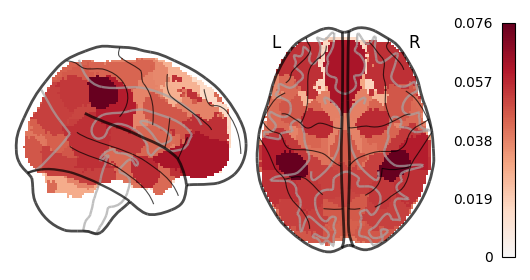

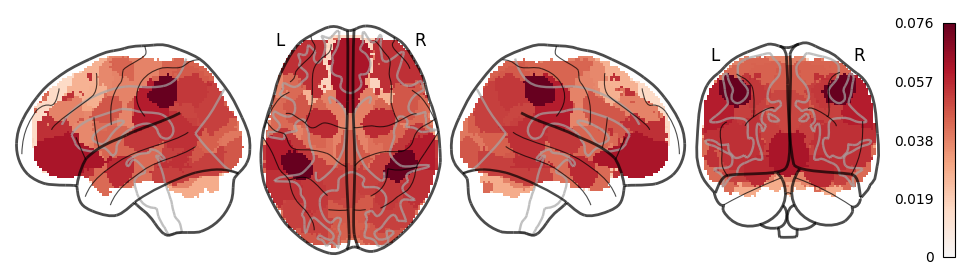

In [20]:
from nilearn.plotting import plot_glass_brain

ROI_corr_big5_brain = roi_to_brain(ROI_corr_big5, mask_x)

plot_glass_brain(ROI_corr_big5_brain.to_nifti(), display_mode='xz',colorbar=True,cmap='RdBu_r',plot_abs=False)
plot_glass_brain(ROI_corr_big5_brain.to_nifti(), display_mode='lzry',colorbar=True,cmap='RdBu_r',plot_abs=False)




In [21]:
corr_temporal

,corr,participants,video
0,-0.070468,sub-sid001377,Nature
0,0.017116,sub-sid001377,Asian cake
0,-0.443558,sub-sid001377,Ribbon climbing
0,-0.560682,sub-sid001377,Kiss me
0,-0.357675,sub-sid001377,Syrian
...,...,...,...
0,-0.240066,sub-sid000861,Lapse
0,-0.054929,sub-sid000861,Newsroom
0,0.392152,sub-sid000861,Russian
0,-0.141501,sub-sid000861,Burgers


### use mixed effect model to test significance

In [32]:
from pymer4.models import Lmer

ROI_corr_big5_t = []
ROI_corr_big5_p = []
ROI_corr_big5_mean = []


for roi_num in range(50):
    ISC_within_corr_all_np_reshape = temporal_ISC(roi_num)
    corr_temporal = pd.DataFrame()
    
    for sub_id,sub_name in enumerate(subj_sids_iteration):
        for video_id in range(24):
            individual_pd_corr = pd.DataFrame()
            session_matrix = ISC_within_corr_all_np_reshape[sub_id,video_id,:,:]
            y_array_trail = session_matrix[np.triu_indices(5, 1)]


            sub_big5_session_similarity_x = sub_big5_session_similarity[sub_id,:,:]
            big5_trail = sub_big5_session_similarity_x[np.triu_indices(5, 1)]
            data = pd.DataFrame(np.array([big5_trail,y_array_trail]).T,columns = ['big5','temporal corr'])
            
            results_corr = data.corr().iloc[0,1]
            individual_pd_corr = pd.DataFrame(np.array([results_corr,sub_name,onset_movie.index[video_id]]).reshape((-1, 3)),columns = ['corr','participants','video'])

            corr_temporal = pd.concat([corr_temporal,individual_pd_corr])


        corr_temporal['corr']=corr_temporal['corr'].astype(float)
        
    model = Lmer("corr ~  ( 1 | participants) + ( 1 | video)", data=corr_temporal)
    ROI_corr_big5_t.append(model.fit().head().iloc[0,5])
    ROI_corr_big5_p.append(model.fit().head().iloc[0,6])
    ROI_corr_big5_mean.append(model.fit().head().iloc[0,0])

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -198.193 	 AIC: 404.386

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.004  0.064
Residual                   0.129  0.360

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -198.193 	 AIC: 404.386

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.004

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -177.077 	 AIC: 362.153

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002  0.047
Residual                   0.119  0.345

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -177.077 	 AIC: 362.153

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -177.728 	 AIC: 363.456

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.021
participants  (Intercept)  0.000  0.000
Residual                   0.121  0.348

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -177.728 	 AIC: 363.456

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.021
participants  (Intercept)  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -169.630 	 AIC: 347.259

Random effects:

                     Name    Var    Std
video         (Intercept)  0.004  0.066
participants  (Intercept)  0.002  0.039
Residual                   0.113  0.336

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -169.630 	 AIC: 347.259

Random effects:

                     Name    Var    Std
video         (Intercept)  0.004  0.066
participants  (Intercept)  0.002  0.039
Residual                   0.113  0.336

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -178.131 	 AIC: 364.262

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.021  0.145
Residual                   0.114  0.337

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -178.131 	 AIC: 364.262

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.021

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -172.791 	 AIC: 353.581

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.034
participants  (Intercept)  0.003  0.058
Residual                   0.115  0.340

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -172.791 	 AIC: 353.581

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.034
participants  (Intercept)  0.003  0.058
Residual                   0.115  0.340

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -185.919 	 AIC: 379.838

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000  0.022
Residual                   0.125  0.354

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -185.919 	 AIC: 379.838

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -173.991 	 AIC: 355.983

Random effects:

                     Name   Var    Std
video         (Intercept)  0.00  0.000
participants  (Intercept)  0.00  0.000
Residual                   0.12  0.346

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -173.991 	 AIC: 355.983

Random effects:

                     Name   Var    Std
video         (Intercept)  0.00  0.000
participants  (Intercept)  0.00  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -161.611 	 AIC: 331.223

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.040
participants  (Intercept)  0.001  0.035
Residual                   0.111  0.333

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -161.611 	 AIC: 331.223

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.040
participants  (Intercept)  0.001  0.035
Residual                   0.111  0.333

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -186.178 	 AIC: 380.357

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.002
participants  (Intercept)  0.001  0.032
Residual                   0.125  0.353

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -186.178 	 AIC: 380.357

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.002
participants  (Intercept)  0.001  0.032
Residual                   0.125  0.353

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -184.352 	 AIC: 376.704

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.001  0.029
Residual                   0.124  0.352

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -184.352 	 AIC: 376.704

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.001

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -161.542 	 AIC: 331.084

Random effects:

                     Name    Var    Std
video         (Intercept)  0.005  0.068
participants  (Intercept)  0.006  0.076
Residual                   0.107  0.326

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -161.542 	 AIC: 331.084

Random effects:

                     Name    Var    Std
video         (Intercept)  0.005  0.068
participants  (Intercept)  0.006  0.076
Residual                   0.107  0.326

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -166.303 	 AIC: 340.607

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002  0.045
Residual                   0.114  0.338

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -166.303 	 AIC: 340.607

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -178.670 	 AIC: 365.340

Random effects:

                     Name    Var    Std
video         (Intercept)  0.005  0.068
participants  (Intercept)  0.009  0.094
Residual                   0.114  0.337

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -178.670 	 AIC: 365.340

Random effects:

                     Name    Var    Std
video         (Intercept)  0.005  0.068
participants  (Intercept)  0.009  0.094
Residual                   0.114  0.337

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -186.450 	 AIC: 380.899

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.001  0.024
Residual                   0.125  0.354

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -186.450 	 AIC: 380.899

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.001

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -157.324 	 AIC: 322.649

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.007  0.081
Residual                   0.108  0.328

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -157.324 	 AIC: 322.649

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.007

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -175.214 	 AIC: 358.428

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003  0.056
Residual                   0.118  0.343

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -175.214 	 AIC: 358.428

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -164.747 	 AIC: 337.494

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002  0.043
Residual                   0.113  0.337

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -164.747 	 AIC: 337.494

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -172.802 	 AIC: 353.604

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.034
participants  (Intercept)  0.000  0.018
Residual                   0.118  0.343

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -172.802 	 AIC: 353.604

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.034
participants  (Intercept)  0.000  0.018
Residual                   0.118  0.343

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -188.403 	 AIC: 384.806

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000  0.000
Residual                   0.127  0.356

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -188.403 	 AIC: 384.806

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -164.135 	 AIC: 336.270

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.020
participants  (Intercept)  0.014  0.117
Residual                   0.108  0.329

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -164.135 	 AIC: 336.270

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.020
participants  (Intercept)  0.014  0.117
Residual                   0.108  0.329

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -169.919 	 AIC: 347.838

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003  0.052
Residual                   0.115  0.340

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -169.919 	 AIC: 347.838

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -196.299 	 AIC: 400.598

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002  0.049
Residual                   0.129  0.360

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -196.299 	 AIC: 400.598

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -169.392 	 AIC: 346.784

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.047
participants  (Intercept)  0.000  0.000
Residual                   0.115  0.340

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -169.392 	 AIC: 346.784

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.047
participants  (Intercept)  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -175.698 	 AIC: 359.396

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.007  0.085
Residual                   0.116  0.341

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -175.698 	 AIC: 359.396

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.007

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -183.231 	 AIC: 374.462

Random effects:

                     Name    Var   Std
video         (Intercept)  0.003  0.05
participants  (Intercept)  0.000  0.00
Residual                   0.122  0.35

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -183.231 	 AIC: 374.462

Random effects:

                     Name    Var   Std
video         (Intercept)  0.003  0.05
participants  (Intercept)  0.000  0.00

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -165.394 	 AIC: 338.788

Random effects:

                     Name    Var    Std
video         (Intercept)  0.004  0.066
participants  (Intercept)  0.001  0.030
Residual                   0.111  0.334

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -165.394 	 AIC: 338.788

Random effects:

                     Name    Var    Std
video         (Intercept)  0.004  0.066
participants  (Intercept)  0.001  0.030
Residual                   0.111  0.334

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -160.657 	 AIC: 329.315

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.031
participants  (Intercept)  0.005  0.069
Residual                   0.109  0.330

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -160.657 	 AIC: 329.315

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.031
participants  (Intercept)  0.005  0.069
Residual                   0.109  0.330

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -189.598 	 AIC: 387.196

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000  0.000
Residual                   0.128  0.357

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -189.598 	 AIC: 387.196

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -199.511 	 AIC: 407.023

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003  0.051
Residual                   0.131  0.362

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -199.511 	 AIC: 407.023

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -156.107 	 AIC: 320.215

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.004  0.060
Residual                   0.108  0.329

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -156.107 	 AIC: 320.215

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.004

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -145.732 	 AIC: 299.464

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002  0.047
Residual                   0.105  0.323

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -145.732 	 AIC: 299.464

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.002

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -177.753 	 AIC: 363.507

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000  0.000
Residual                   0.121  0.348

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -177.753 	 AIC: 363.507

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -163.556 	 AIC: 335.112

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.040
participants  (Intercept)  0.002  0.044
Residual                   0.111  0.334

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -163.556 	 AIC: 335.112

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.040
participants  (Intercept)  0.002  0.044
Residual                   0.111  0.334

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -176.814 	 AIC: 361.628

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.022
participants  (Intercept)  0.004  0.063
Residual                   0.118  0.343

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -176.814 	 AIC: 361.628

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.022
participants  (Intercept)  0.004  0.063
Residual                   0.118  0.343

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -200.911 	 AIC: 409.821

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.040
participants  (Intercept)  0.007  0.086
Residual                   0.128  0.358

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -200.911 	 AIC: 409.821

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.040
participants  (Intercept)  0.007  0.086
Residual                   0.128  0.358

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -164.071 	 AIC: 336.142

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.004  0.061
Residual                   0.112  0.335

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -164.071 	 AIC: 336.142

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.004

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -181.640 	 AIC: 371.280

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003  0.051
Residual                   0.121  0.348

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -181.640 	 AIC: 371.280

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -179.088 	 AIC: 366.175

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.023
participants  (Intercept)  0.006  0.078
Residual                   0.118  0.343

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -179.088 	 AIC: 366.175

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.023
participants  (Intercept)  0.006  0.078
Residual                   0.118  0.343

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -174.290 	 AIC: 356.580

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.001  0.033
Residual                   0.119  0.345

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -174.290 	 AIC: 356.580

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.001

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -157.037 	 AIC: 322.073

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.022
participants  (Intercept)  0.002  0.042
Residual                   0.109  0.331

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -157.037 	 AIC: 322.073

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.022
participants  (Intercept)  0.002  0.042
Residual                   0.109  0.331

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -172.340 	 AIC: 352.679

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000  0.000
Residual                   0.119  0.345

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -172.340 	 AIC: 352.679

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.000

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -181.893 	 AIC: 371.787

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003  0.051
Residual                   0.122  0.349

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -181.893 	 AIC: 371.787

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.003

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -178.816 	 AIC: 365.632

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.044
participants  (Intercept)  0.014  0.120
Residual                   0.114  0.337

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -178.816 	 AIC: 365.632

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.044
participants  (Intercept)  0.014  0.120
Residual                   0.114  0.337

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -193.203 	 AIC: 394.407

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.030
participants  (Intercept)  0.000  0.004
Residual                   0.129  0.359

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -193.203 	 AIC: 394.407

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.030
participants  (Intercept)  0.000  0.004
Residual                   0.129  0.359

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -158.230 	 AIC: 324.459

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.020
participants  (Intercept)  0.003  0.050
Residual                   0.110  0.331

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -158.230 	 AIC: 324.459

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.020
participants  (Intercept)  0.003  0.050
Residual                   0.110  0.331

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -171.645 	 AIC: 351.289

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.033
participants  (Intercept)  0.014  0.120
Residual                   0.111  0.333

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -171.645 	 AIC: 351.289

Random effects:

                     Name    Var    Std
video         (Intercept)  0.001  0.033
participants  (Intercept)  0.014  0.120
Residual                   0.111  0.333

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -166.995 	 AIC: 341.990

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.050
participants  (Intercept)  0.000  0.016
Residual                   0.114  0.337

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -166.995 	 AIC: 341.990

Random effects:

                     Name    Var    Std
video         (Intercept)  0.002  0.050
participants  (Intercept)  0.000  0.016
Residual                   0.114  0.337

No random effect correlations specified

Fixed effects:

Linear mixed model fit by REML [’lmerMod’]
F

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -182.856 	 AIC: 373.712

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.005  0.073
Residual                   0.121  0.347

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -182.856 	 AIC: 373.712

Random effects:

                     Name    Var    Std
video         (Intercept)  0.000  0.000
participants  (Intercept)  0.005

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -166.091 	 AIC: 340.182

Random effects:

                     Name    Var   Std
video         (Intercept)  0.000  0.00
participants  (Intercept)  0.000  0.00
Residual                   0.116  0.34

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

Linear mixed model fit by REML [’lmerMod’]
Formula: corr~(1|participants)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'participants': 20.0}

Log-likelihood: -166.091 	 AIC: 340.182

Random effects:

                     Name    Var   Std
video         (Intercept)  0.000  0.00
participants  (Intercept)  0.000  0.00

In [94]:
model.coefs

,Estimate,2.5_ci,97.5_ci,SE,DF,T-stat,P-val,Sig
(Intercept),0.023924,-0.00929,0.057139,0.016947,22.625128,1.41175,0.171629,


In [96]:
model.fixef

[                 (Intercept)
 1 second            0.012259
 Angelina Hale       0.034242
 Asian cake          0.035881
 Burgers             0.038504
 Cookies             0.025318
 Dancing lady        0.022243
 Family              0.018555
 Farewell            0.025205
 Ingrid Silva        0.021979
 Kiss me             0.023901
 Lapse               0.007580
 Lasagna             0.036888
 Nature              0.019176
 Newsroom            0.042705
 Porn                0.009440
 Ramen               0.037403
 Ribbon climbing     0.029723
 Russian             0.045336
 Salad               0.017518
 Skiing              0.022249
 Sky surfing         0.012478
 Soccer              0.014713
 Syrian              0.009267
 The present         0.011627,
                (Intercept)
 sub-sid000381     0.023924
 sub-sid000780     0.023924
 sub-sid000846     0.023924
 sub-sid000854     0.023924
 sub-sid000861     0.023924
 sub-sid001274     0.023924
 sub-sid001276     0.023924
 sub-sid001277     0.0239

In [23]:
ROI_corr_big5_p

[0.188,
 0.013,
 0.364,
 0.112,
 0.282,
 0.02,
 0.013,
 0.066,
 0.067,
 0.035,
 0.042,
 0.062,
 0.006,
 0.311,
 0.335,
 0.021,
 0.209,
 0.026,
 0.279,
 0.002,
 0.24,
 0.034,
 0.186,
 0.16,
 0.084,
 0.008,
 0.097,
 0.052,
 0.013,
 0.83,
 0.31,
 0.018,
 0.0,
 0.06,
 0.096,
 0.059,
 0.044,
 0.283,
 0.046,
 0.268,
 0.07,
 0.076,
 0.013,
 0.159,
 0.054,
 0.08,
 0.213,
 0.034,
 0.004,
 0.006]

In [86]:
fdr_thr = fdr(np.array(ROI_corr_big5_p))
sig_roi = np.array(list(range(50)))[np.array(ROI_corr_big5_p <= fdr_thr)]

In [87]:
sig_roi

array([19, 32])

In [69]:
fdr_thr

0.002

In [89]:
print(ROI_corr_big5_t[32],ROI_corr_big5_p[32],ROI_corr_big5_mean[32])

3.887 0.0 0.062


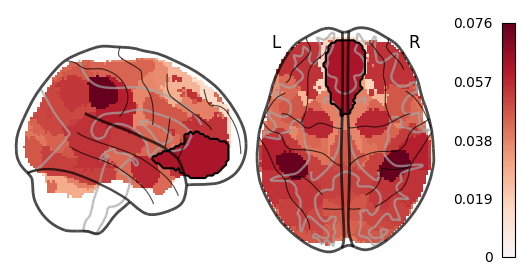

In [73]:
from nilearn.plotting import plot_glass_brain

ROI_corr_big5_brain = roi_to_brain(ROI_corr_big5_mean, mask_x)

display = plot_glass_brain(ROI_corr_big5_brain.to_nifti(), display_mode='xz',colorbar=True,cmap='RdBu_r',plot_abs=False)

[display.add_contours(mask_x[x].to_nifti(), levels=[0.5], colors='black', alpha=1) for x in sig_roi]
plt.savefig(os.path.join(current_directory,svg_file,"big_five_2_fdr.svg"), format="svg")


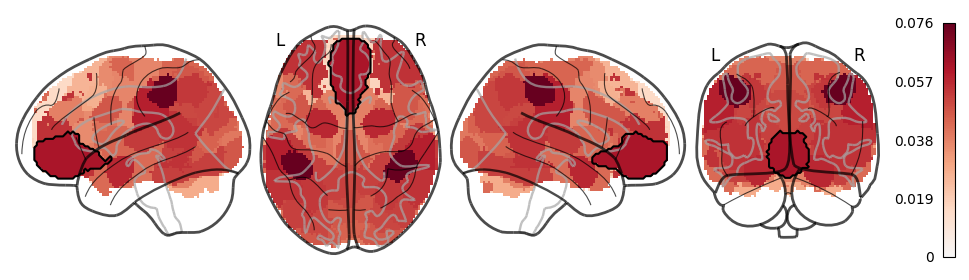

In [39]:
display = plot_glass_brain(ROI_corr_big5_brain.to_nifti(), display_mode='lzry',colorbar=True,cmap='RdBu_r',plot_abs=False)
[display.add_contours(mask_x[x].to_nifti(), levels=[0.5], colors='black', alpha=1) for x in sig_roi]
plt.savefig(os.path.join(current_directory,svg_file,"big_five_4_fdr.svg"), format="svg")

In [13]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist,squareform

In [12]:
base_dir = '/Storage/Data/nes_menghan/liquidsword2_materials/'
preference_all = os.path.join(base_dir,'preference','NES_PreferenceData_Long.csv')
preference_all = pd.read_csv(preference_all)
preference_all

,Unnamed: 0,Ranking,Subject,Video_Image,Run,Video,Ranking_Normalized
0,video1_1,11,s000,video1_1,1,nature,0.785714
1,video2_1,9,s000,video2_1,1,social_kindness,0.642857
2,video3_1,9,s000,video3_1,1,sexual,0.642857
3,video4_1,9,s000,video4_1,1,singing_girl,0.642857
4,video5_2,3,s000,video5_2,1,1_sec_day,0.214286
...,...,...,...,...,...,...,...
3931,video28_1,5,s64,video28_1,1,ramen,0.454545
3932,video29_5,6,s64,video29_5,1,bmx,0.545455
3933,video30_1,10,s64,video30_1,1,burgers,0.909091
3934,video31_4,11,s64,video31_4,1,ingrid,1.000000


In [14]:
sub_name = preference_all.groupby(by='Subject').sum()['Run']
sub_name = sub_name[sub_name==360]
sub_name = sub_name.keys()
sub_name_exclude = ['s30','s38','s31','s005','s15']##subj_sids_iteration.remove('sub-sid001215') 
##subj_sids_iteration.remove('sub-sid001473')
### head coil issue: HEP
sub_name_dict = {'s001':'sub-sid001274',
                 's003':'sub-sid001276',
                 's004':'sub-sid001277',
                 's006':'sub-sid000780',
                 's007':'sub-sid000861',
                 's008':'sub-sid001278',
                 's009':'sub-sid001280',
                 's11':'sub-sid001282',
                 's12':'sub-sid001286',
                 's16':'sub-sid001291',
                 's18':'sub-sid001296',
                 's21':'sub-sid001302',
                 's23':'sub-sid000846',
                 's24':'sub-sid001358',
                 's25':'sub-sid001377',
                 's32':'sub-sid000854',
                 's35':'sub-sid001397',
                 's36':'sub-sid001367',
                 's40':'sub-sid000381',
                 's41':'sub-sid001555'}

In [43]:
sub_name_behavior_keys = [k for k,v in sub_name_dict.items() if v == 'sid001274']

In [44]:
sub_name_behavior_keys

[]

In [9]:
video_dict = {'nature':onset_movie.index[0],
              'social_kindness':onset_movie.index[1],
              'sexual':onset_movie.index[15],
              'singing_girl':onset_movie.index[6],
              '1_sec_day':onset_movie.index[14],
              'syria':onset_movie.index[4],
              'soccer':onset_movie.index[7],
              'woman_dancing':onset_movie.index[8],
              'newsroom':onset_movie.index[20],
              'family':onset_movie.index[17],
              'russian_circus':onset_movie.index[21],
              'farewell':onset_movie.index[11],
              'the_present':onset_movie.index[18],
              'sky_surfing':onset_movie.index[9],
              'salad':onset_movie.index[5],
              'skiing':onset_movie.index[13],
              'lasagna':onset_movie.index[10],
              'romance':onset_movie.index[3],
              'cookies':onset_movie.index[12],
              'ramen':onset_movie.index[16],
              'bmx':onset_movie.index[19],
              'burgers':onset_movie.index[22],
              'ingrid':onset_movie.index[23],
              'aerial':onset_movie.index[2]}

In [46]:
a = list(video_dict.values())
a.index(onset_movie.index[13])


15

### all preference variability

  0%|          | 0/20 [00:00<?, ?it/s]

/tmp/ipykernel_3443628/1675324522.py:38: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  sub_fig, _ = plt.subplots(figsize=(6,5))


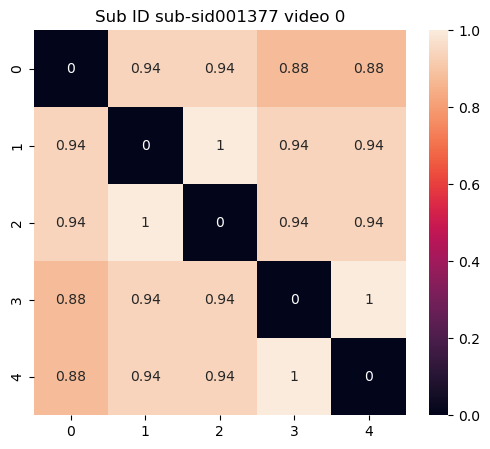

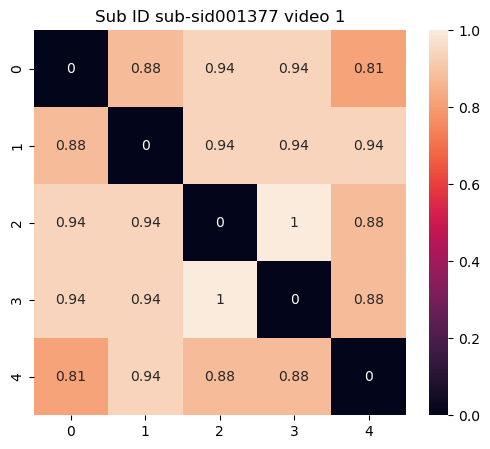

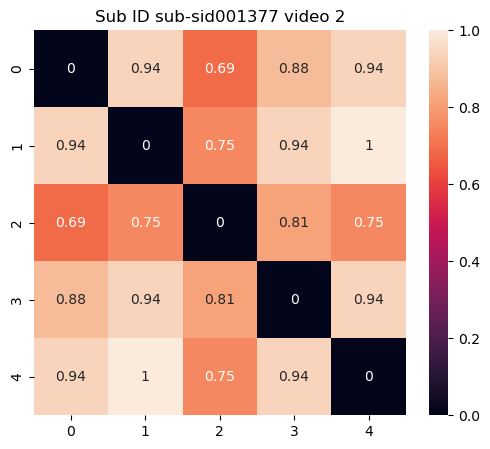

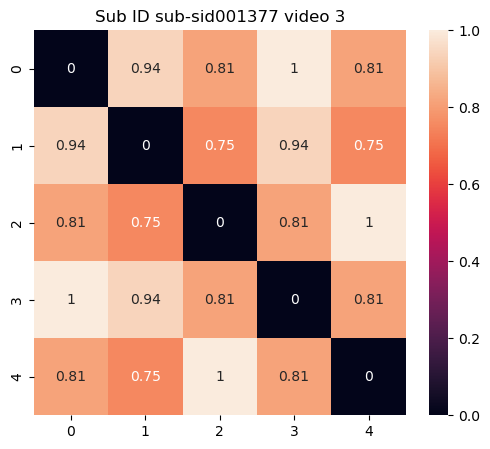

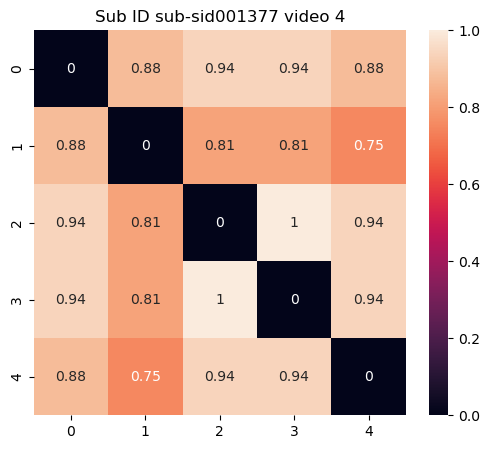

...

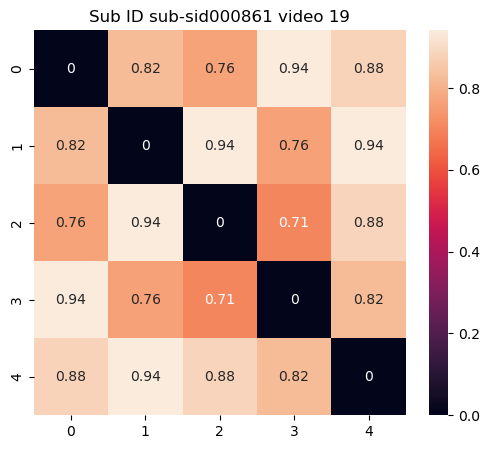

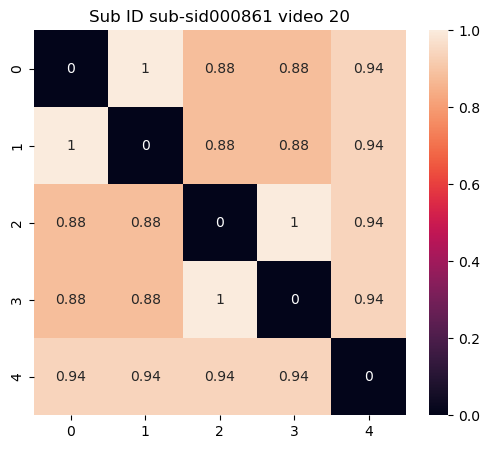

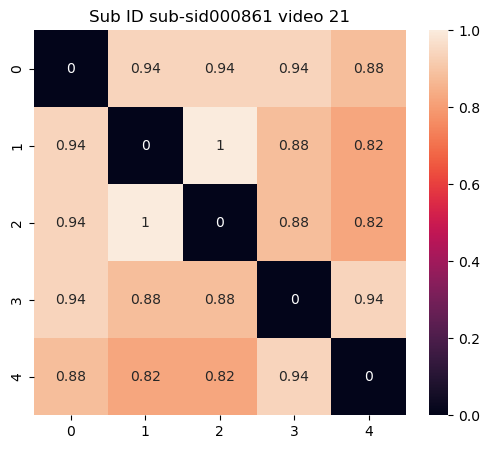

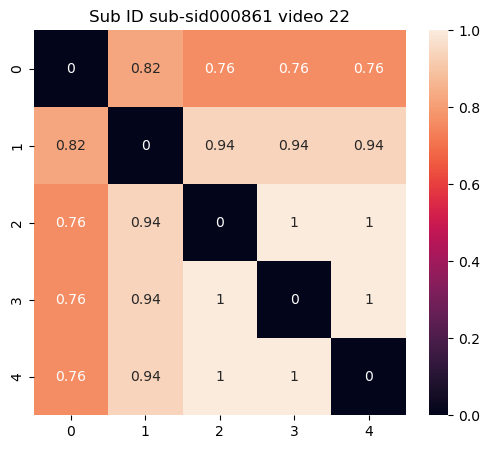

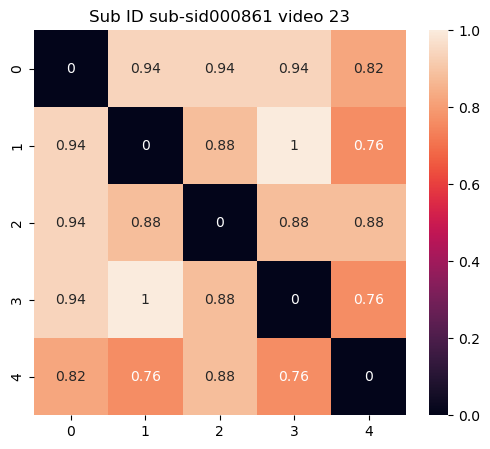

In [15]:
from tqdm.notebook import tqdm
import glob
import glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


roi_num = 4
session_num = 5

onset_movie = os.path.join('/Storage/Data/nes_menghan/', 'code_menghan', 'NeuroExperience','onset_movie.txt')
onset_movie = pd.read_csv(onset_movie,sep='\t').set_index('Movie name')

suball_movie_corr_V1 = pd.DataFrame()
ISC_within_corr_all_V1 = []

sub_video_preference_corr_all = np.zeros((5,5))

video_name_all = list(video_dict.values())

for sub_name in tqdm(subj_sids_iteration):
    sub_name_behavior_keys = [k for k,v in sub_name_dict.items() if v == sub_name] ## behavioral data identifier

    for video_label in range(24):

        sub_pref = preference_all.query('Subject == @sub_name_behavior_keys').pivot(index='Video', columns='Run', values='Ranking_Normalized')
        video_num = video_name_all.index(onset_movie.index[video_label])
        sub_pref_video = sub_pref.iloc[video_num]
        sub_pref_video = pd.DataFrame(sub_pref_video)
        
        video_session_distance = Adjacency(squareform(pdist(sub_pref_video.values, metric = 'euclidean')), matrix_type="distance")
        video_session_similarity = Adjacency.distance_to_similarity(video_session_distance)
        sub_video_preference_corr = video_session_similarity.squareform()
        sub_video_preference_corr_all = sub_video_preference_corr_all + sub_video_preference_corr

        sub_fig, _ = plt.subplots(figsize=(6,5))
        sns.heatmap(sub_video_preference_corr,annot=True).set(title = 'Sub ID ' + str(sub_name) + ' video ' + str(video_label))



In [48]:
squareform(pdist(sub_pref_video.values, metric = 'euclidean'))

array([[0.        , 0.05882353, 0.05882353, 0.05882353, 0.17647059],
       [0.05882353, 0.        , 0.11764706, 0.        , 0.23529412],
       [0.05882353, 0.11764706, 0.        , 0.11764706, 0.11764706],
       [0.05882353, 0.        , 0.11764706, 0.        , 0.23529412],
       [0.17647059, 0.23529412, 0.11764706, 0.23529412, 0.        ]])

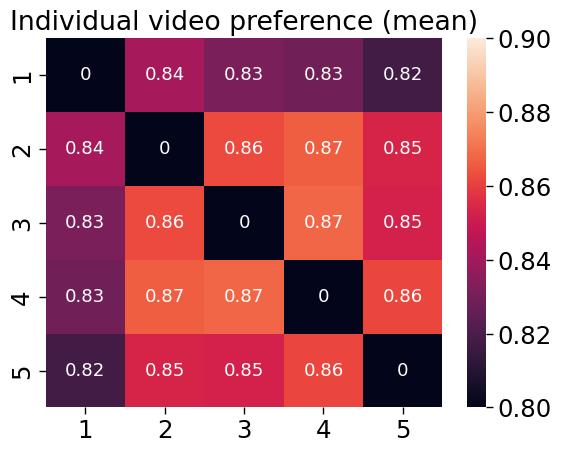

In [36]:
yticks = [1,2,3,4,5]
with sns.plotting_context(context='paper',font_scale=2):
    sns.heatmap(sub_video_preference_corr_all/(24*20),annot=True,vmin = 0.8, vmax = 0.9, annot_kws={"size": 13},yticklabels=yticks,xticklabels=yticks).set(title = 'Individual video preference (mean)')
#     plt.ylim(0, 1)
    
plt.savefig(os.path.join(current_directory,svg_file,"video_preference.svg"), format="svg")

In [51]:
from scipy import stats

ISC_preference_corr_all = []
pvalue_results = []


for roi_num in tqdm(range(50)):
    suball_movie_corr_brain = pd.DataFrame()

    for sub_name in tqdm(subj_sids_iteration):
        sub_name_behavior_keys = [k for k,v in sub_name_dict.items() if v == sub_name] ## behavioral data identifier
        data_subj_session = pd.DataFrame([])
        isc_data = glob.glob(os.path.join('/Storage/Data/nes_menghan/denoised/Denoised_ROI',f"{sub_name}_ses*_Denoised_ROI_{roi_num}.csv"))
        isc_data.sort()
        for i in range(session_num):
            isc_data_session = pd.read_csv(isc_data[i])
            if len(data_subj_session) == 0:
                data_subj_session = isc_data_session
            else:
                data_subj_session = np.concatenate((data_subj_session,isc_data_session),axis = 1)

        video_corr = []
    #         video_corr_data = []
        for video_label in range(24):
            video_sess = []
            video_onset = onset_movie['Entire Onset'][video_label]-1
            video_end = onset_movie['Entire Ending'][video_label]-1
            video_sess = data_subj_session[video_onset:video_end+1,:] 
            video_data = pd.DataFrame(video_sess)
    #             video_data = video_data.T
            video_data_corr = video_data.corr() ## neural corr data
            video_data_corr = np.array(video_data_corr)
            video_data_corr_trail = video_data_corr[np.triu_indices(5, 1)]

            sub_pref = preference_all.query('Subject == @sub_name_behavior_keys').pivot(index='Video', columns='Run', values='Ranking_Normalized')
            video_num = video_name_all.index(onset_movie.index[video_label])
            sub_pref_video = sub_pref.iloc[video_num]
            sub_pref_video = pd.DataFrame(sub_pref_video)
            
            video_session_distance = Adjacency(squareform(pdist(sub_pref_video.values, metric = 'euclidean')), matrix_type="distance")
            video_session_similarity = Adjacency.distance_to_similarity(video_session_distance)
            sub_video_preference_corr = video_session_similarity.squareform()
             ## behavioral corr data
            sub_video_preference_corr_trail = sub_video_preference_corr[np.triu_indices(5, 1)]
            
            neural_preference = pd.DataFrame(video_data_corr_trail,sub_video_preference_corr_trail).reset_index()
            neural_preference_corr = neural_preference.corr(method = 'spearman')

            sub_corr = pd.DataFrame(np.array([neural_preference_corr.iloc[1,0],sub_name,onset_movie.index[video_label],'Vmpfc'])).T
            sub_corr.columns = ['corr_data','subject','video','brain region']
            suball_movie_corr_brain = suball_movie_corr_brain.append(sub_corr)
            
    suball_movie_corr_brain['corr_data']=suball_movie_corr_brain['corr_data'].astype(float)
    mean_preference = pd.DataFrame(suball_movie_corr_brain.groupby('subject')['corr_data'].mean())
    stats_result = stats.ttest_1samp(mean_preference['corr_data'].values, popmean=0, alternative='greater')
    
    pvalue_results.append(stats_result.pvalue)
    ISC_preference_corr_all.append(suball_movie_corr_brain['corr_data'].mean())

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

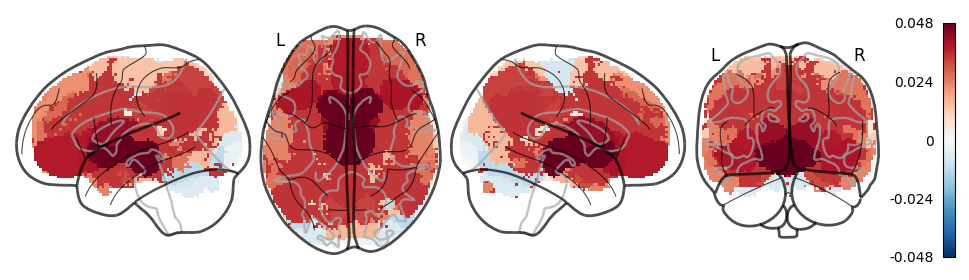

In [52]:
from nilearn.plotting import plot_glass_brain
ISC_preference = roi_to_brain(ISC_preference_corr_all, mask_x)
plot_glass_brain(ISC_preference.to_nifti(), display_mode='lzry',colorbar=True,cmap='RdBu_r',plot_abs=False)

In [54]:
from scipy import stats

ROI_corr_preference_t = []
ROI_corr_preference_p = []
ROI_corr_preference_mean = []


for roi_num in tqdm(range(50)):
    suball_movie_corr_brain = pd.DataFrame()

    for sub_name in tqdm(subj_sids_iteration):
        sub_name_behavior_keys = [k for k,v in sub_name_dict.items() if v == sub_name] ## behavioral data identifier
        data_subj_session = pd.DataFrame([])
        isc_data = glob.glob(os.path.join('/Storage/Data/nes_menghan/denoised/Denoised_ROI',f"{sub_name}_ses*_Denoised_ROI_{roi_num}.csv"))
        isc_data.sort()
        for i in range(session_num):
            isc_data_session = pd.read_csv(isc_data[i])
            if len(data_subj_session) == 0:
                data_subj_session = isc_data_session
            else:
                data_subj_session = np.concatenate((data_subj_session,isc_data_session),axis = 1)

        video_corr = []
    #         video_corr_data = []
        for video_label in range(24):
            video_sess = []
            video_onset = onset_movie['Entire Onset'][video_label]-1
            video_end = onset_movie['Entire Ending'][video_label]-1
            video_sess = data_subj_session[video_onset:video_end+1,:] 
            video_data = pd.DataFrame(video_sess)
    #             video_data = video_data.T
            video_data_corr = video_data.corr() ## neural corr data
            video_data_corr = np.array(video_data_corr)
            video_data_corr_trail = video_data_corr[np.triu_indices(5, 1)]

            sub_pref = preference_all.query('Subject == @sub_name_behavior_keys').pivot(index='Video', columns='Run', values='Ranking_Normalized')
            video_num = video_name_all.index(onset_movie.index[video_label])
            sub_pref_video = sub_pref.iloc[video_num]
            sub_pref_video = pd.DataFrame(sub_pref_video)
            
            video_session_distance = Adjacency(squareform(pdist(sub_pref_video.values, metric = 'euclidean')), matrix_type="distance")
            video_session_similarity = Adjacency.distance_to_similarity(video_session_distance)
            sub_video_preference_corr = video_session_similarity.squareform()
             ## behavioral corr data
            sub_video_preference_corr_trail = sub_video_preference_corr[np.triu_indices(5, 1)]
            
            neural_preference = pd.DataFrame(video_data_corr_trail,sub_video_preference_corr_trail).reset_index()
            neural_preference_corr = neural_preference.corr(method = 'spearman')

            sub_corr = pd.DataFrame(np.array([neural_preference_corr.iloc[1,0],sub_name,onset_movie.index[video_label],'Vmpfc'])).T
            sub_corr.columns = ['corr_data','subject','video','brain region']
            suball_movie_corr_brain = suball_movie_corr_brain.append(sub_corr)
            
    suball_movie_corr_brain['corr_data']=suball_movie_corr_brain['corr_data'].astype(float)
    
    model = Lmer("corr_data ~  ( 1 | subject) + ( 1 | video)", data=suball_movie_corr_brain)
    ROI_corr_preference_t.append(model.fit().head().iloc[0,5])
    ROI_corr_preference_p.append(model.fit().head().iloc[0,6])
    ROI_corr_preference_mean.append(model.fit().head().iloc[0,0])

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -156.278 	 AIC: 320.557

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.002  0.043
Residual               0.110  0.332

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -172.993 	 AIC: 353.985

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.036
subject   (Intercept)  0.003  0.051
Residual               0.117  0.341

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -165.765 	 AIC: 339.530

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.017
subject   (Intercept)  0.001  0.024
Residual               0.115  0.340

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -139.655 	 AIC: 287.310

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.104  0.323

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -170.129 	 AIC: 348.257

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.011
subject   (Intercept)  0.000  0.018
Residual               0.118  0.343

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -168.770 	 AIC: 345.541

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.118  0.343

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -158.990 	 AIC: 325.981

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.007
subject   (Intercept)  0.000  0.010
Residual               0.113  0.336

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -153.395 	 AIC: 314.790

Random effects:

                 Name   Var    Std
video     (Intercept)  0.00  0.000
subject   (Intercept)  0.00  0.000
Residual               0.11  0.332

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you h

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -150.730 	 AIC: 309.460

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.027
subject   (Intercept)  0.001  0.029
Residual               0.108  0.328

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -169.512 	 AIC: 347.025

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.034
Residual               0.117  0.342

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -152.417 	 AIC: 312.833

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.036
Residual               0.109  0.330

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -147.222 	 AIC: 302.445

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.107  0.328

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -170.266 	 AIC: 348.532

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.026
subject   (Intercept)  0.000  0.021
Residual               0.117  0.343

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -176.658 	 AIC: 361.316

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.025
subject   (Intercept)  0.000  0.012
Residual               0.121  0.348

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -146.935 	 AIC: 301.870

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.009
subject   (Intercept)  0.001  0.026
Residual               0.107  0.327

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -180.368 	 AIC: 368.737

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.124  0.351

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -154.607 	 AIC: 317.214

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.111  0.333

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -155.891 	 AIC: 319.783

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.023
Residual               0.111  0.333

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -161.189 	 AIC: 330.377

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.023
Residual               0.113  0.337

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -166.616 	 AIC: 341.231

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.022
subject   (Intercept)  0.000  0.000
Residual               0.116  0.341

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -182.515 	 AIC: 373.029

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.016
subject   (Intercept)  0.000  0.000
Residual               0.124  0.353

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -178.139 	 AIC: 364.278

Random effects:

                 Name    Var   Std
video     (Intercept)  0.000  0.00
subject   (Intercept)  0.000  0.00
Residual               0.122  0.35

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you h

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -171.502 	 AIC: 351.004

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.119  0.345

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -159.880 	 AIC: 327.760

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.003  0.052
Residual               0.111  0.334

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -181.393 	 AIC: 370.785

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.021
Residual               0.124  0.352

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -150.204 	 AIC: 308.408

Random effects:

                 Name    Var   Std
video     (Intercept)  0.000  0.00
subject   (Intercept)  0.000  0.00
Residual               0.109  0.33

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you h

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -158.207 	 AIC: 324.414

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.017
subject   (Intercept)  0.000  0.000
Residual               0.112  0.335

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -166.895 	 AIC: 341.791

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.029
subject   (Intercept)  0.003  0.052
Residual               0.114  0.337

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -175.292 	 AIC: 358.584

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.031
subject   (Intercept)  0.001  0.030
Residual               0.119  0.345

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -173.816 	 AIC: 355.633

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.027
Residual               0.120  0.346

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -160.938 	 AIC: 329.877

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.036
Residual               0.113  0.336

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -187.799 	 AIC: 383.598

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.127  0.357

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -155.224 	 AIC: 318.449

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.111  0.333

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -155.992 	 AIC: 319.984

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.032
subject   (Intercept)  0.002  0.047
Residual               0.109  0.330

No random effect correlations specified

Fixed effects:

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have row

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -154.891 	 AIC: 317.782

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.111  0.333

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -180.397 	 AIC: 368.795

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.124  0.351

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -173.816 	 AIC: 355.632

Random effects:

                 Name   Var    Std
video     (Intercept)  0.00  0.000
subject   (Intercept)  0.00  0.014
Residual               0.12  0.346

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you h

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -179.225 	 AIC: 366.450

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.031
Residual               0.122  0.349

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -172.665 	 AIC: 353.330

Random effects:

                 Name   Var    Std
video     (Intercept)  0.00  0.000
subject   (Intercept)  0.00  0.007
Residual               0.12  0.346

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you h

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -159.119 	 AIC: 326.237

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.113  0.336

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -172.401 	 AIC: 352.802

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.002  0.045
Residual               0.118  0.343

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -159.784 	 AIC: 327.568

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.037
Residual               0.112  0.335

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -172.094 	 AIC: 352.187

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.119  0.345

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -154.500 	 AIC: 317.000

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.111  0.333

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -160.114 	 AIC: 328.229

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.001  0.024
Residual               0.113  0.336

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -170.286 	 AIC: 348.572

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.118  0.344

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -148.902 	 AIC: 305.805

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.108  0.329

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -161.753 	 AIC: 331.506

Random effects:

                 Name    Var    Std
video     (Intercept)  0.002  0.046
subject   (Intercept)  0.000  0.000
Residual               0.112  0.335

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -171.103 	 AIC: 350.205

Random effects:

                 Name    Var    Std
video     (Intercept)  0.000  0.000
subject   (Intercept)  0.000  0.000
Residual               0.119  0.345

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

  0%|          | 0/20 [00:00<?, ?it/s]

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because you have rows with NaNs in your data.

**NOTE** Column for 'fits' not created in model.data, but saved in model.fits only. This is because you have rows with NaNs in your data.

Linear mixed model fit by REML [’lmerMod’]
Formula: corr_data~(1|subject)+(1|video)

Family: gaussian	 Inference: parametric

Number of observations: 480	 Groups: {'video': 24.0, 'subject': 20.0}

Log-likelihood: -171.267 	 AIC: 350.534

Random effects:

                 Name    Var    Std
video     (Intercept)  0.001  0.031
subject   (Intercept)  0.000  0.000
Residual               0.118  0.344

No random effect correlations specified

Fixed effects:

boundary (singular) fit: see help('isSingular') 

boundary (singular) fit: see help('isSingular') 

**NOTE**: Column for 'residuals' not created in model.data, but saved in model.resid only. This is because y

In [55]:
ROI_corr_preference_p

[0.176,
 0.814,
 0.217,
 0.749,
 0.865,
 0.66,
 0.062,
 0.002,
 0.654,
 0.19,
 0.62,
 0.409,
 0.093,
 0.491,
 0.054,
 0.742,
 0.15,
 0.047,
 0.028,
 0.042,
 0.674,
 0.507,
 0.104,
 0.445,
 0.364,
 0.085,
 0.39,
 0.953,
 0.383,
 0.023,
 0.439,
 0.425,
 0.013,
 0.208,
 0.002,
 0.863,
 0.413,
 0.035,
 0.936,
 0.14,
 0.508,
 0.706,
 0.531,
 0.981,
 0.106,
 0.759,
 0.96,
 0.84,
 0.172,
 0.172]

In [74]:
fdr_thr = fdr(np.array(ROI_corr_preference_p),q=0.05)
sig_roi = np.array(list(range(50)))[np.array(ROI_corr_preference_p <= fdr_thr)]

In [75]:
sig_roi

array([ 7, 34])

In [84]:
print(ROI_corr_preference_t[7],ROI_corr_preference_p[7],ROI_corr_preference_mean[7])

3.174 0.002 0.048


In [85]:
print(ROI_corr_preference_t[34],ROI_corr_preference_p[34],ROI_corr_preference_mean[34])

3.127 0.002 0.048


In [58]:
fdr_thr

0.002

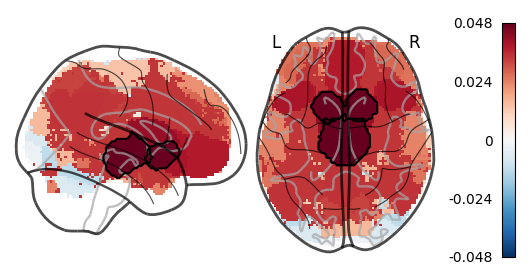

In [81]:
from nilearn.plotting import plot_glass_brain
ISC_preference = roi_to_brain(ISC_preference_corr_all, mask_x)
display = plot_glass_brain(ISC_preference.to_nifti(), display_mode='xz',colorbar=True,cmap='RdBu_r',plot_abs=False)

[display.add_contours(mask_x[x].to_nifti(), levels=[0.5], colors='black', alpha=1) for x in sig_roi]
plt.savefig(os.path.join(current_directory,svg_file,"preference_2_fdr.svg"), format="svg")



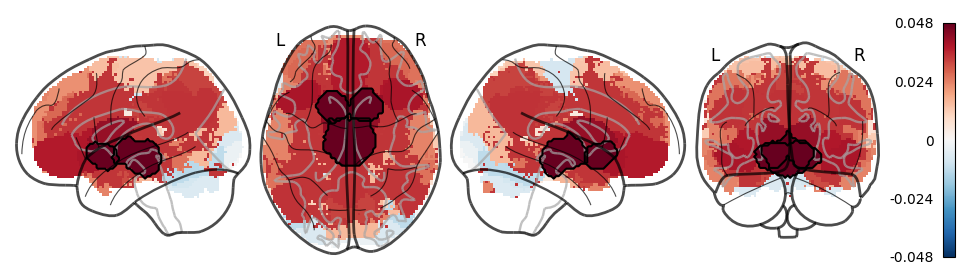

In [76]:
from nilearn.plotting import plot_glass_brain
ISC_preference = roi_to_brain(ISC_preference_corr_all, mask_x)
display = plot_glass_brain(ISC_preference.to_nifti(), display_mode='lzry',colorbar=True,cmap='RdBu_r',plot_abs=False)

[display.add_contours(mask_x[x].to_nifti(), levels=[0.5], colors='black', alpha=1) for x in sig_roi]
plt.savefig(os.path.join(current_directory,svg_file,"preference_4_fdr.svg"), format="svg")



In [78]:
print(ROI_corr_preference_t[32],ROI_corr_preference_p[32],ROI_corr_preference_mean[32])

2.498 0.013 0.038


In [79]:
roi_name = ['anterior MPFC',
            'Fusiform/parahippocampus',
            'DMPFC',
            'Sensorimotor/Postcentral Gyrus',
            'V1',
            'TPJ posterior supra marginal/angular gyrus',
            'PCC/precuneus',
            'Thalamus',
            'SMA',
            'Precentral Gyrus',
            'Cerebellum (VI',
            'Temporal Occipital Fusiform',
            'Amygdala',
            'Superior Temporal Gyrus',
            'white matter',
            'TPJ anterior supra marginal gyrus/Parietal operculum',
            'mid insula',
            'putamen',
            'Dorsal Anterior Insula',
            'PCC/Superior LOC',
            'Lateral Occipital/Temporal Occibpital (V2)',
            '21',
            'dACC ',
            'anterior fronto-parietal (dlpfc, dacc)',
            'Intercalcarine cortex',
            'Anterior vlpfc',
            'left motor',
            'Left IFG',
            'hippocampus',
            'Dorsal Caudate',
            '30',
            '31',
            'vmPFC ',
            '33',
            'Nacc',
            'Primary Auditory',
            '36',
            'Ventral Anterior Insula',
            '38',
            'Superior LOC',
            '40',
            '41',
            'Cerebellum (Crus)',
            '43',
            'DLPFC',
            'right IFG vlpfc',
            'inferior LOC',
            'right motor',
            'somatosensory',
            'STS']

In [80]:
print(roi_name[7],roi_name[34])

Thalamus Nacc


In [88]:
print(roi_name[19])

PCC/Superior LOC
